# Visión por Computador - Práctica 3 - Deep Learning en Computer Vision

#### 20 puntos   |   Fecha de entrega: 20 de diciembre de 2026, 23:59   |   Forma de entrega: a través de la tarea creada en https://pradogrado2627.ugr.es/

### Estudiante: <mark>POR FAVOR, INTRODUZCA AQUÍ SU NOMBRE COMPLETO</mark>

## Normas de desarrollo y entrega de la práctica

1. Para este trabajo, al igual que para los demás, se debe presentar código, resultados, discusión de los mismos, y presentación y análisis del trabajo realizado, todo integrado en el propio Google Colab Notebook (es decir, no se entrega ninguna memoria separada en `.pdf` ni ningún código `.py`). Se recuerda que código y resultados sin informe explicativo no puntúa. Resulta también fundamental recordar que solo se acepta la entrega de ficheros `.ipynb` (no resulta válido entregar un fichero `.py`).

2. En relación con el punto anterior, se recuerda que se proporciona un Notebook, denominado `Ejemplo_Otsu.ipynb`, que muestra un ejemplo de respuesta y solución a un potencial ejercicio. El propósito de este Notebook es servir de referencia al alumnado acerca de cómo responder los ejercicios planteados. Véase que, por ejemplo, en aras de diferenciar con facilidad enunciados y respuestas, estas últimas se presentan en otro color (azul, en ese caso).

3. El diseño de celdas del documento debe ser respetado. Es decir, no se puede modificar el orden de los ejercicios o alterar la estructura del Notebook, de forma que dificulte localizar los contenidos. Aunque sí se puede, por ejemplo, crear nuevas subsecciones dentro de las secciones ya existentes para estructurar y organizar con más claridad las respuestas, así como para incluir los experimentos extra que se deseen.

4. Tal y como se muestra en `Ejemplo_Otsu.ipynb`, no hay ningún problema en emplear técnicas de IA generativa (como ChatGPT o Gemini) para crear el código de los distintos ejercicios o para enriquecer el análisis y descripción del trabajo realizado (aunque, obvia decirlo, su uso no es obligatorio). Pero, en caso de usarse, sí se debe aclarar de qué modo se ha usado la IA, con qué objetivo, y se debe demostrar que se entiende perfectamente lo que se ha hecho.

5. Solo se entregará el fichero `.ipynb` (incorporando código, resultados, y explicación del trabajo realizado y los resultados obtenidos) y no se enviarán las imágenes empleadas. El path para la lectura de imágenes, o cualquier otro fichero de entrada, debe ser siempre “/content/drive/My Drive/images/nombre_fichero” (salvo que se indique lo contrario explícitamente en un ejercicio concreto; por ejemplo, si un ejercicio determina una ubicación propia para un determinado conjunto de datos).

6. El código deberá  presentarse adecuadamente comentado y con los resultados obtenidos en cada apartado, junto con la presentación del trabajo realizado y la discusión y análisis de los resultados obtenidos. Es importante reiterar que la entrega de código sin informe explicativo o valoraciones no puntúa. Por otro lado, el código debe ir comentado en comentarios en celdas de código, mientras que el análisis y discusión, tanto del trabajo realizado como de los resultados obtenidos, debe ir en celdas de texto.

Este trabajo de implementación tiene como objetivo principal **familiarizarse con la implementación y diseño de redes convolucionales para problemas de visión por computador**.




### Materiales de Apoyo

En caso de que el alumnado tenga dudas sobre Python, OpenCV o el uso de Google Colab, se recuerda que en PRADO hay materiales de apoyo (https://pradogrado2627.ugr.es/mod/folder/view.php?id=83733):
-  Introducción a Python: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/1.%20Introduccion%20a%20Python.pdf
- Introducción a NumPy, Matplotlib y Scikit-learn: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/2.%20Introducci%C3%B3n%20a%20Numpy%20Matplotlib%20y%20sklearn.pdf
- Notebook con toda la información anterior (y más cosas): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_Python.ipynb
- Ejercicios y ejemplos de repaso: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/3.%20Ejercicios%20y%20ejemplos%20de%20repaso.pdf
- Fundamentos de Python para lectura, visualización y manipulación de imágenes: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/4.%20Fundamentos%20de%20Python%20para%20manipulacion%20de%20imagenes.pdf(y Notebook asociado: https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Guia_fundamentos_imagenes.ipynb)
- Ideas sobre cómo redactar un documento académico-científico (útil para saber cómo documentar las respuestas a los ejercicios, el Notebook en su conjunto, y la memoria del proyecto final o de un TFG/TFM): https://pradogrado2627.ugr.es/pluginfile.php/153447/mod_folder/content/0/Algunas%20ideas%20sobre%20c%C3%B3mo%20elaborar%20un%20informe%20acad%C3%A9mico-cient%C3%ADfico.pdf
- Ejemplo de respuesta a un hipotético ejercicio sobre el algoritmo de umbralización de Otsu: https://pradogrado2627.ugr.es/pluginfile.php/153448/mod_folder/content/0/Ejemplo_Otsu.ipynb

# <font color='blue'>Ejercicio 4: Clasificación, explicabilidad y segmentación en Oxford-IIIT Pet (5 puntos)</font>

<font color='blue'>En este ejercicio utilizaremos el conjunto de datos [Oxford-IIIT Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), formado por imágenes de perros y gatos de 37 razas. Cada imagen incluye una etiqueta de raza y una máscara a nivel de píxel. Se abordarán dos problemas diferentes sobre las mismas imágenes: clasificación de razas con Grad-CAM (apartado 4.A, 2 puntos) y segmentación del animal respecto al fondo (apartado 4.B, 3 puntos).</font>

<font color='blue'>Se respetará la separación oficial `trainval`/`test`. Se reservará el $20\%$ de `trainval` para validación, con semilla 42, utilizando exactamente los mismos ejemplos de entrenamiento, validación y test en ambos apartados. Todas las imágenes se procesarán a una resolución de $224 × 224$ píxeles. </font>

<font color='blue'>En todos los apartados, al igual que en los ejercicios anteriores, se debe proporcionar código comentado, descripción de los modelos y de los parámetros entrenables, resultados cuantitativos, visualizaciones e interpretación crítica. No basta con presentar código y métricas. Para este dataset descargado automáticamente se utilizará la ruta devuelta por `untar_data(URLs.PETS)`, como excepción a las indicaciones generales de lectura de archivos desde Google Drive.</font>

<font color='blue'>Referencias: [dataset original](https://www.robots.ox.ac.uk/~vgg/data/pets/), [fastai: clasificación de mascotas](https://docs.fast.ai/tutorial.vision.html), [fastai: segmentación](https://docs.fast.ai/examples/camvid.html).</font>


## <font color='blue'>Preparación del entorno y de los datos (común a los apartados 4.A y 4.B)

<font color='blue'>Utilizamos la API de fastai, como en el ejercicio anterior. Es importante activar la GPU en `Entorno de ejecución > Cambiar tipo de entorno de ejecución` de Colab antes de entrenar.


In [ ]:
# The first thing we should do is to apply hardware acceleration via GPU.
# Go to Editar - Configuración del cuaderno - Acelerador por hardware - GPU.

# SET UP fastai
!pip install -Uqq fastbook
!pip install -q nbdev
!pip install -q grad-cam

import fastbook
fastbook.setup_book()

import fastai
import fastcore

print(f'fastcore version {fastcore.__version__} installed')
print(f'fastai version {fastai.__version__} installed')

from nbdev.showdoc import *
from fastai.vision.all import *

# Additional libraries required for Exercise 4
from torchvision.models import densenet121, resnet18

# Grad-CAM
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

# Evaluation metrics
from sklearn.metrics import accuracy_score, f1_score

# Additional utilities
import matplotlib.pyplot as plt
import numpy as np
import torch
import time
from pathlib import Path

# Reproducibility
set_seed(42, reproducible=True)

# Hardware configuration
print('PyTorch version:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())

if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))

USE_FP16 = torch.cuda.is_available()
NUM_WORKERS = 2

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Mounted at /content/gdrive
fastcore version 2.2.35 installed
fastai version 2.8.12 installed
PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
# Descargar imágenes y anotaciones una sola vez. fastai reutiliza el directorio
# descargado en ejecuciones posteriores del mismo entorno.
path = untar_data(URLs.PETS)
print('Directorio del dataset:', path)
print('Subdirectorios:', path.ls())

assert (path/'images').is_dir(), 'No se encuentra la carpeta images.'
assert (path/'annotations'/'trimaps').is_dir(), 'No se encuentra la carpeta de máscaras.'
assert (path/'annotations'/'trainval.txt').is_file(), 'Falta trainval.txt.'
assert (path/'annotations'/'test.txt').is_file(), 'Falta test.txt.'


<div><progress max="811706944" value="811712512"></progress> 100.00% [811712512/811706944 09:02&lt;00:00]</div>

Directorio del dataset: /root/.fastai/data/oxford-iiit-pet
Subdirectorios: [Path('/root/.fastai/data/oxford-iiit-pet/images'), Path('/root/.fastai/data/oxford-iiit-pet/annotations')]


<font color='blue'>El dataset Oxford-IIIT Pet proporciona, para cada fotografía, una máscara de segmentación denominada *trimap*. Las fotografías se encuentran en `path/'images'` (archivos JPG), mientras que sus correspondientes máscaras están almacenadas en `path/'annotations'/'trimaps'` (archivos PNG). Cada fotografía y su máscara comparten el mismo nombre base. Cada *trimap* es una imagen de un solo canal cuyos píxeles contienen tres posibles valores:
- <font color='blue'>**1:** animal (*foreground*).
- **2:** fondo (*background*).
- **3:** contorno del animal o región no clasificada inequívocamente (*uncertain boundary*).



<font color='blue'>El dataset proporciona archivos de texto que identifican qué imágenes pertenecen a `trainval` y cuáles al test oficial. En lugar de mover o duplicar imágenes entre carpetas, definiremos los índices de validación y los reutilizaremos en ambos experimentos.

In [ ]:
def images_from_split(txt_path):
    # La primera columna de cada fila es el nombre base, sin extensión.
    names = [line.split()[0] for line in txt_path.read_text().splitlines()
             if line.strip()]
    files = [path/'images'/f'{name}.jpg' for name in names]
    missing = [f for f in files if not f.is_file()]
    if missing:
        raise FileNotFoundError(f'Faltan {len(missing)} imágenes; ejemplo: {missing[0]}')
    return files

trainval_files = images_from_split(path/'annotations'/'trainval.txt')
test_files = images_from_split(path/'annotations'/'test.txt')

rng = np.random.default_rng(42)
n_valid = round(0.20 * len(trainval_files))
valid_idxs = sorted(
    rng.choice(
        len(trainval_files),
        size=n_valid,
        replace=False
    ).tolist()
)


## <font color='blue'>4.A. Clasificación y explicabilidad con Grad-CAM (2 puntos)</font>

<font color='blue'>**4.A.1. Entrenamiento de un clasificador (0.5 puntos).** Se utilizará DenseNet121 preentrenada en ImageNet para clasificar las 37 razas. Se debe incorporar una cabecera personalizada basada en *global average pooling* y una única capa completamente conectada, justificar sus dimensiones y realizar un ajuste fino de la red (1 época entrenando inicialmente la cabecera y 5 épocas de fine-tuning posterior). Se exige `summary()`, identificación de los parámetros entrenables, así como accuracy y macro-F1 sobre el test oficial. Muy probablemente, DenseNet121 alcanzará una accuracy de validación muy elevada después de una única época de entrenamiento de la cabecera. ¿A qué crees que se puede deber?</font>

<font color='blue'>**4.A.2. Grad-CAM y comparación con las máscaras reales (1 punto).** Se aplicará Grad-CAM sobre las activaciones del último bloque convolucional de DenseNet121. Es imprescindible identificar ese bloque y comprobar las dimensiones espaciales de sus activaciones. Se visualizarán al menos ocho imágenes del test, incluyendo ejemplos correctamente clasificados y ejemplos incorrectos, cuando existan. Para los ejemplos erróneos se comparará el Grad-CAM de la clase predicha con el de la clase verdadera. Para esas ocho imágenes, se mostrarán también las regiones del animal indicadas por las máscaras del dataset. ¿Coinciden aproximadamente con las regiones destacadas por Grad-CAM?</font>

<font color='blue'>En relación con este apartado recordemos que Grad-CAM es específico de la clase que queremos explicar. Podemos generar distintos mapas para una misma imagen, dependiendo de qué clase seleccionemos. Imaginemos una fotografía de un gato siamés que DenseNet121 clasifica incorrectamente como un gato birmano. Podemos calcular:
- <font color='blue'>Grad-CAM (clase predicha: birmano): "¿Qué regiones de la imagen contribuyen positivamente a la puntuación que el modelo asigna a la clase "birmano"?"
- Grad-CAM (clase real: siamés): "¿Qué regiones contribuyen positivamente a la puntuación que el modelo asigna a la clase "siamés", aunque no haya sido la clase predicha?"

<font color='blue'>**4.A.3. Análisis conceptual de DenseNet121 (0.25 puntos).** Explica con tus propias palabras la arquitectura de DenseNet121, prestando especial atención a las conexiones densas, los bloques densos, las capas de transición y el concepto de *growth rate*. ¿En qué se diferencia fundamentalmente de una ResNet?

<font color='blue'>**4.A.4.  Limitaciones de la explicabilidad (0.25 puntos).** Lee el artículo de Ghassemi et al. (2021), “The false hope of current approaches to explainable artificial intelligence in health care”, y analiza posibles limitaciones de los métodos de explicabilidad que discuten sus autores. Exprésate con tus propias palabras y relaciona tu respuesta con los resultados de Grad-CAM obtenidos en este ejercicio (y con lo ya indicado en el apartado 4.A.2). ¿Hasta qué punto un mapa Grad-CAM permite comprender o justificar la predicción de una red neuronal? Junto con lo anterior, haz una breve búsqueda bibliográfica e indica en qué se diferencian los conceptos de "explicabilidad" e "interpretabilidad" en IA.


<font color='blue'>**Referencias:** [Huang et al., DenseNet (CVPR 2017)](https://arxiv.org/abs/1608.06993); [Selvaraju et al., Grad-CAM (ICCV 2017)](https://arxiv.org/abs/1610.02391); [Ghassemi et al., The false hope of explainable AI in health care (The Lancet Digital Health, 2021)](https://doi.org/10.1016/S2589-7500(21)00208-9); [pytorch-grad-cam (GitHub implementation)](https://github.com/jacobgil/pytorch-grad-cam).</font>



### <font color='blue'>4.A.1. Entrenamiento de un clasificador (0.5 ptos)




<font color='blue'>La clase de cada imagen se obtiene a partir de su nombre: `Abyssinian_100.jpg` corresponde a la raza `Abyssinian`; `american_bulldog_12.jpg`, a `american_bulldog`. Se mantienen exactamente los índices de validación calculados anteriormente.

Clases: 37
Vocabulario: ['Abyssinian', 'Bengal', 'Birman', 'Bombay', 'British_Shorthair', 'Egyptian_Mau', 'Maine_Coon', 'Persian', 'Ragdoll', 'Russian_Blue', 'Siamese', 'Sphynx', 'american_bulldog', 'american_pit_bull_terrier', 'basset_hound', 'beagle', 'boxer', 'chihuahua', 'english_cocker_spaniel', 'english_setter', 'german_shorthaired', 'great_pyrenees', 'havanese', 'japanese_chin', 'keeshond', 'leonberger', 'miniature_pinscher', 'newfoundland', 'pomeranian', 'pug', 'saint_bernard', 'samoyed', 'scottish_terrier', 'shiba_inu', 'staffordshire_bull_terrier', 'wheaten_terrier', 'yorkshire_terrier']


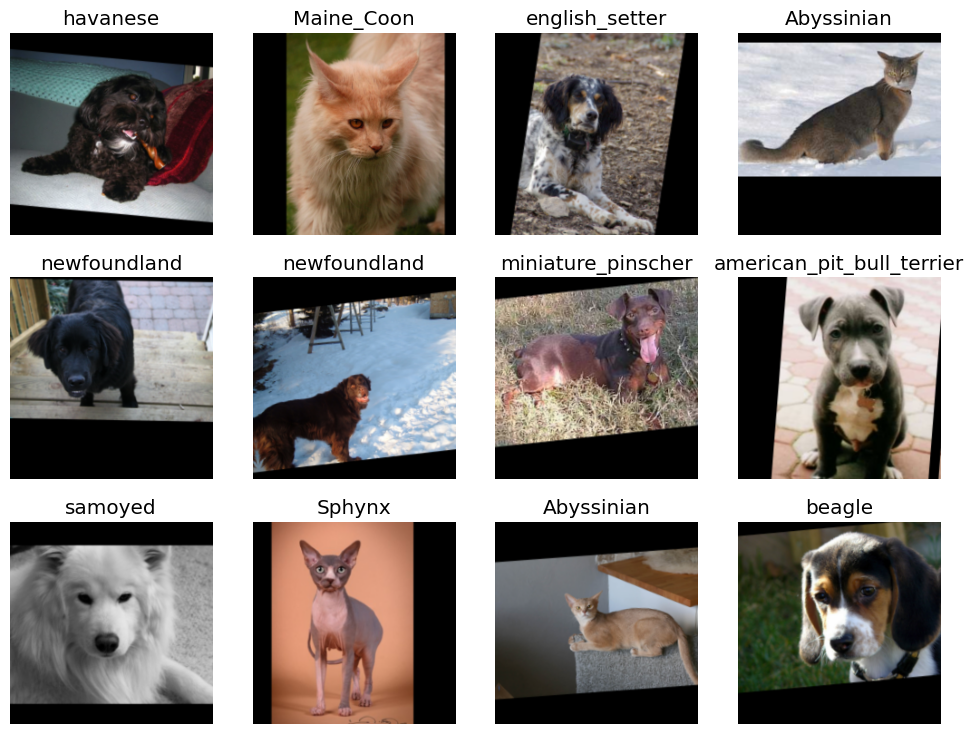

In [ ]:
def breed_label(f):
    # Quitar del nombre el sufijo numérico: raza_NNN.jpg -> raza.
    return '_'.join(f.stem.split('_')[:-1])

pet_classification = DataBlock(
    # A CUBRIR POR EL ALUMNADO
)

dls_cls = pet_classification.dataloaders(# A CUBRIR POR EL ALUMNADO)
dls_cls.show_batch(max_n=12)
print('Clases:', len(dls_cls.vocab))
print('Vocabulario:', list(dls_cls.vocab)[:])

In [ ]:
n_classes = len(dls_cls.vocab)

custom_head_cls = nn.Sequential(
    # A CUBRIR POR EL ALUMNADO
)

learn_cls = vision_learner(
    # A CUBRIR POR EL ALUMNADO
)

# A CUBRIR POR EL ALUMNADO


### <font color='blue'>4.A.2. Grad-CAM y comparación con las máscaras reales (1 pto)




In [ ]:
# A CUBRIR POR EL ALUMNADO


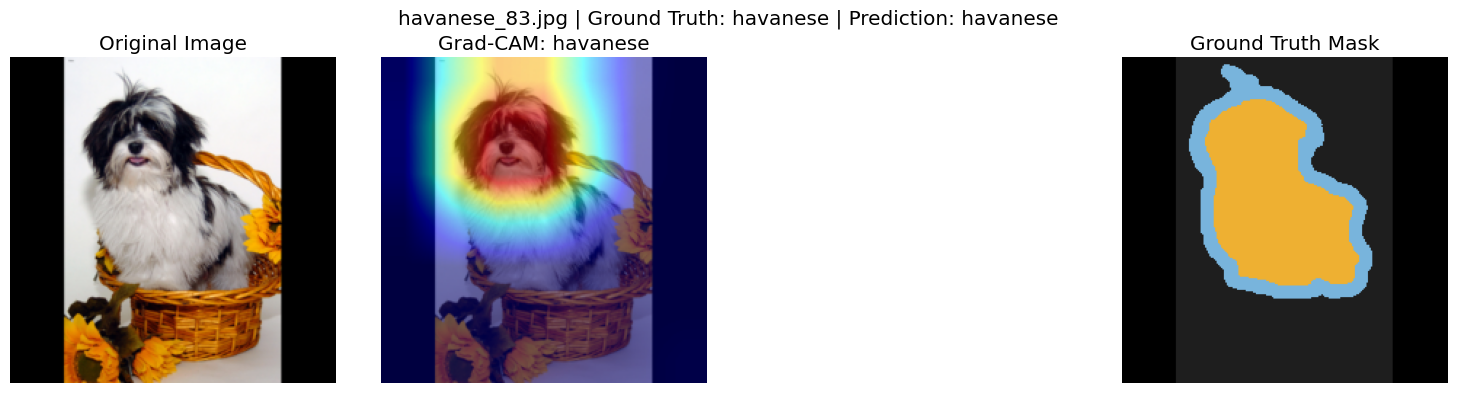

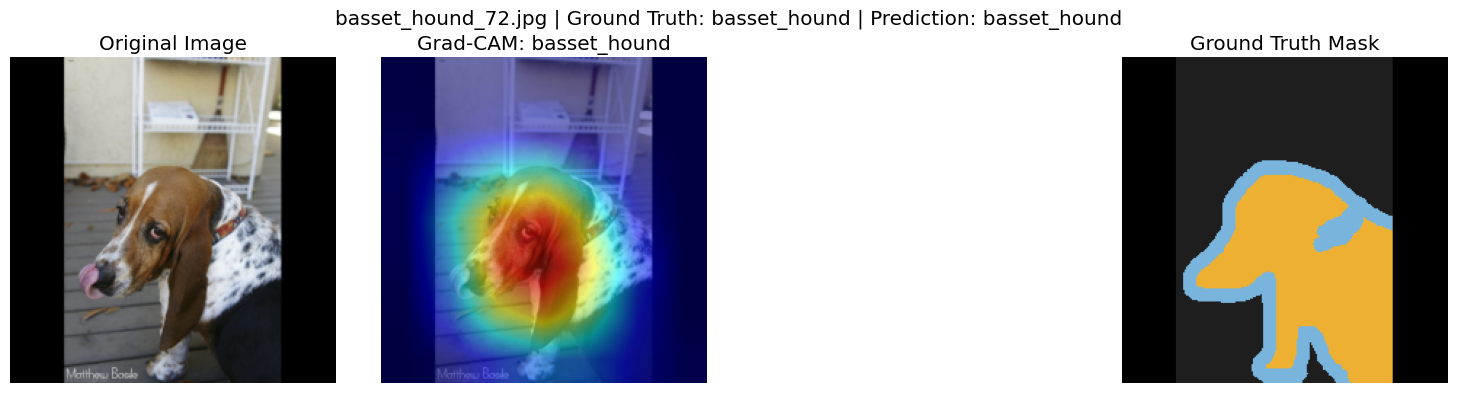

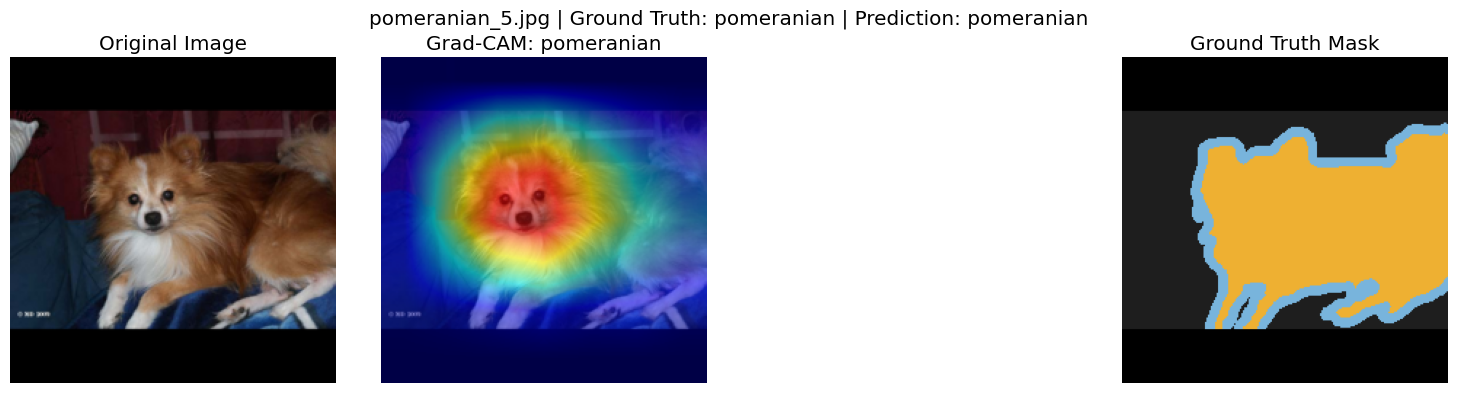

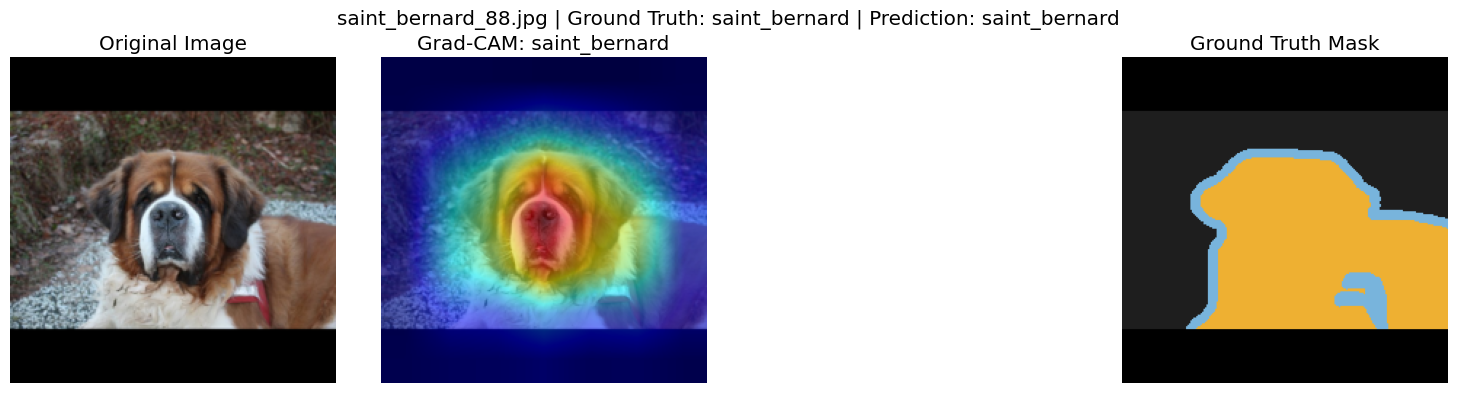

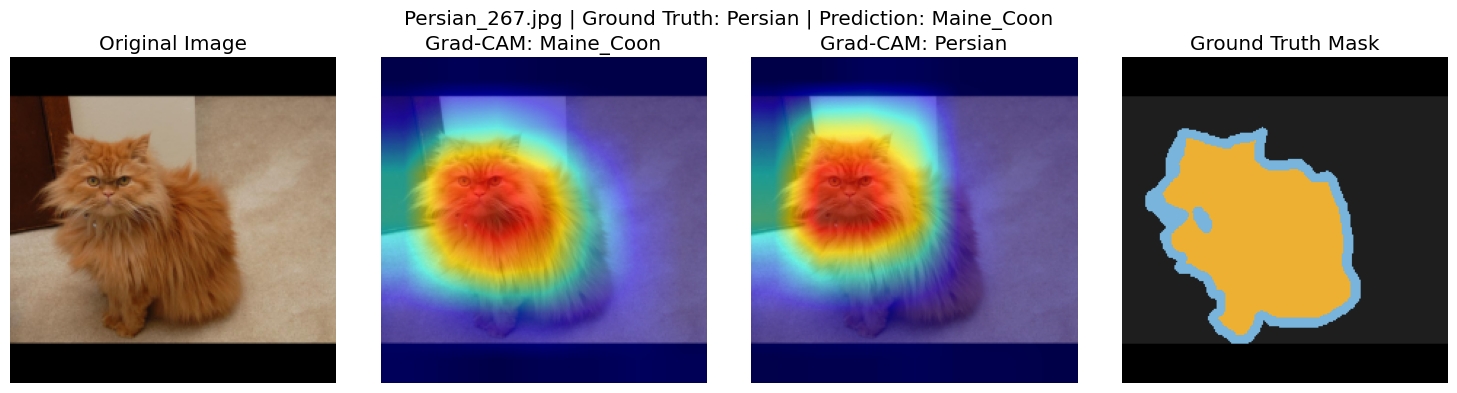

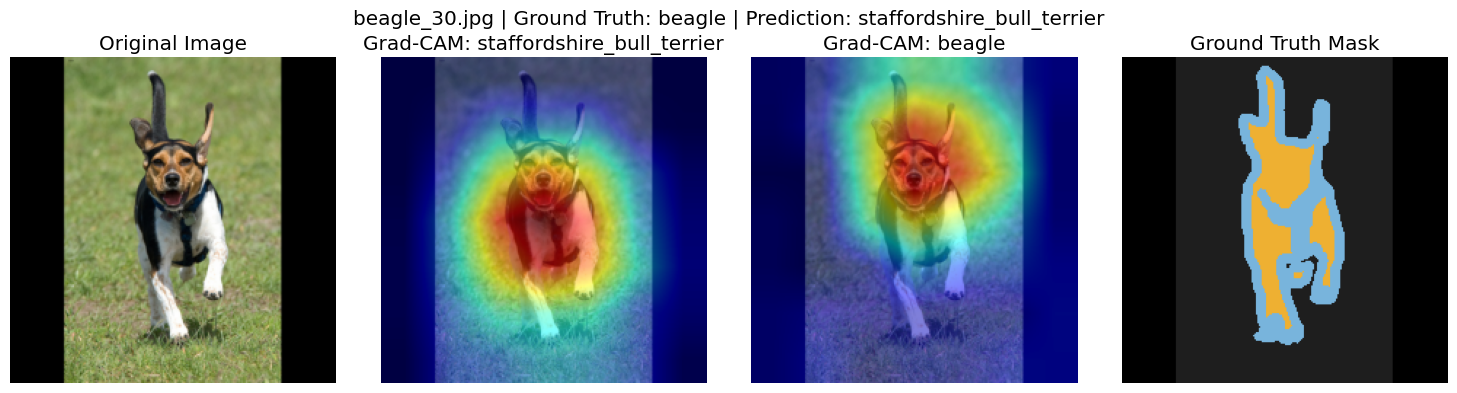

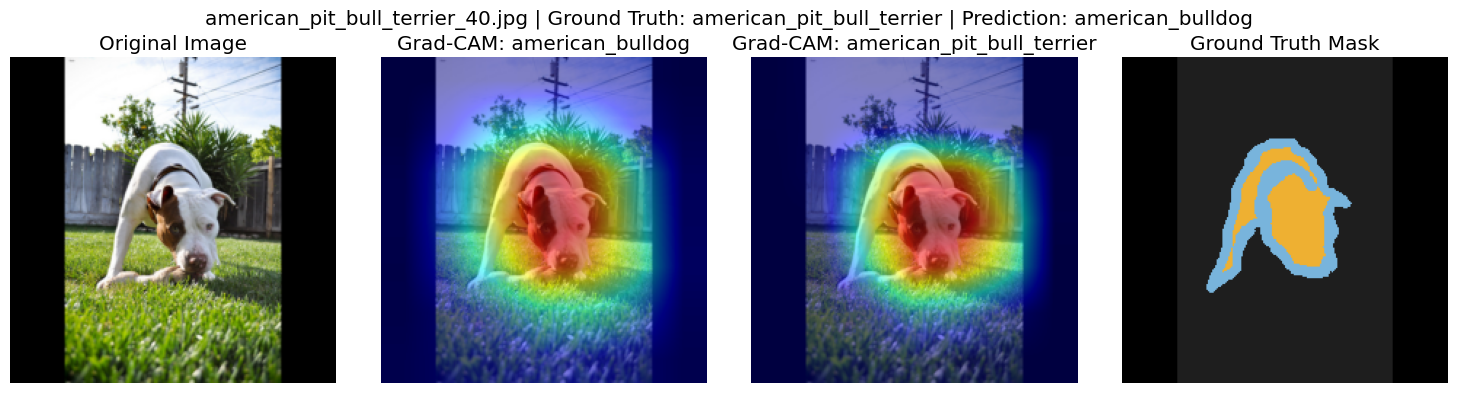

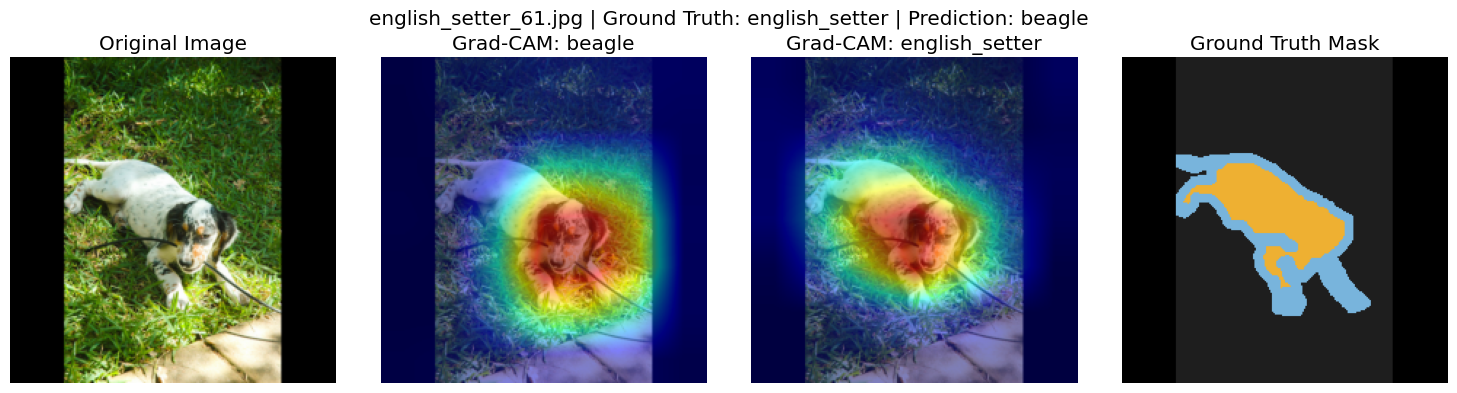

In [ ]:
# A CUBRIR POR EL ALUMNADO


### <font color='blue'>4.A.3. Análisis conceptual de DenseNet121 (0.25 puntos).



### <font color='blue'>4.A.4.  Limitaciones de la explicabilidad (0.25 puntos).

## <font color='blue'>4.B. Segmentación del animal mediante U-Net (3 puntos)

<font color='blue'>A partir de las mismas imágenes y particiones de 4.A, se construirá un `DataBlock` de segmentación (`ImageBlock` y `MaskBlock`). El problema será binario: animal frente a fondo. Las máscaras procesadas deberán utilizar la codificación `0` (fondo), `1` (animal) y `255` (región de contorno incierto, excluida de la evaluación). El alumnado deberá identificar la codificación original de las máscaras de Oxford-IIIT Pet, realizar la conversión correspondiente y explicar cómo se excluyen los píxeles etiquetados con `255` tanto de la función de pérdida como de las métricas de evaluación.  Se visualizarán ejemplos de imágenes y sus máscaras.

<font color='blue'>A continuación, se debe entrenar una U-Net con un encoder ResNet18 preentrenado en ImageNet utilizando `unet_learner`. Se requiere `summary()`, explicar qué aportan encoder, decoder y *skip connections*, justificar la función de pérdida, utilizar una fase inicial congelada y después realizar fine-tuning. Se recomienda limitar la resolución a $224 × 224$ y ajustar el tamaño del batch a la memoria de la GPU disponible.

<font color='blue'>Una vez el modelo haya sido entrenado, se debe evaluar en el test oficial utilizando IoU y coeficiente Dice para la clase animal, excluyendo los píxeles de contorno del cálculo de ambas métricas. Se deben incluir las definiciones matemáticas de ambas métricas y explicar por qué la exactitud por píxel puede resultar engañosa en tareas de segmentación con desbalanceo de clases. Además de IoU y Dice, se deberá calcular la distancia de Hausdorff  entre los contornos de las máscaras predichas y las máscaras reales. Se deberá explicar qué mide esta métrica, cómo se diferencia de IoU y Dice y por qué puede ser especialmente sensible a errores localizados en los contornos. La evaluación mantendrá la política de exclusión de los píxeles de contorno no clasificados de Oxford-IIIT Pet. Para Hausdorff, se utilizarán los contornos de las regiones restringidas a píxeles válidos.

<font color='blue'>Finalmente, se mostrarán al menos ocho ejemplos del conjunto de test, incluyendo, para cada uno, la imagen original, la máscara real, la máscara predicha y el mapa TP/FP/FN/TN, con los píxeles ignorados representados en gris. Dichos mapas utilizarán el siguiente código de colores:
* <font color='blue'>Verde: verdaderos positivos (TP).
* Rojo: falsos positivos (FP).
* Negro: falsos negativos (FN).
* Blanco: verdaderos negativos (TN).
* Gris: píxeles ignorados en la evaluación.
<font color='blue'>Se deberán identificar y comentar errores significativos, prestando especial atención a las regiones del objeto incorrectamente segmentadas, las detecciones falsas sobre el fondo y las dificultades asociadas a los contornos.

<font color='blue'>**Referencias:** [U-Net, MICCAI 2015](https://arxiv.org/abs/1505.04597), [fastai: segmentación con CamVid](https://docs.fast.ai/examples/camvid.html).


<font color='blue'>**Nota sobre las métricas de segmentación.** fastai ya proporciona implementaciones de métricas como `Dice` y `JaccardCoeff` (IoU). Sin embargo, en nuestro ejercicio puede ser necesario definir versiones personalizadas para evaluar específicamente la clase animal y excluir explícitamente los píxeles de contorno etiquetados con `255`.


In [ ]:
def pet_binary_mask(f):
    # A COMPLETAR POR EL ALUMNADO
    # Convertir las etiquetas originales:
    # 1 -> 1, 2 -> 0, 3 -> 255
    ...

In [ ]:
pet_segmentation = DataBlock(
    # A COMPLETAR POR EL ALUMNADO
)

dls_seg = pet_segmentation.dataloaders(# A COMPLETAR POR EL ALUMNADO)

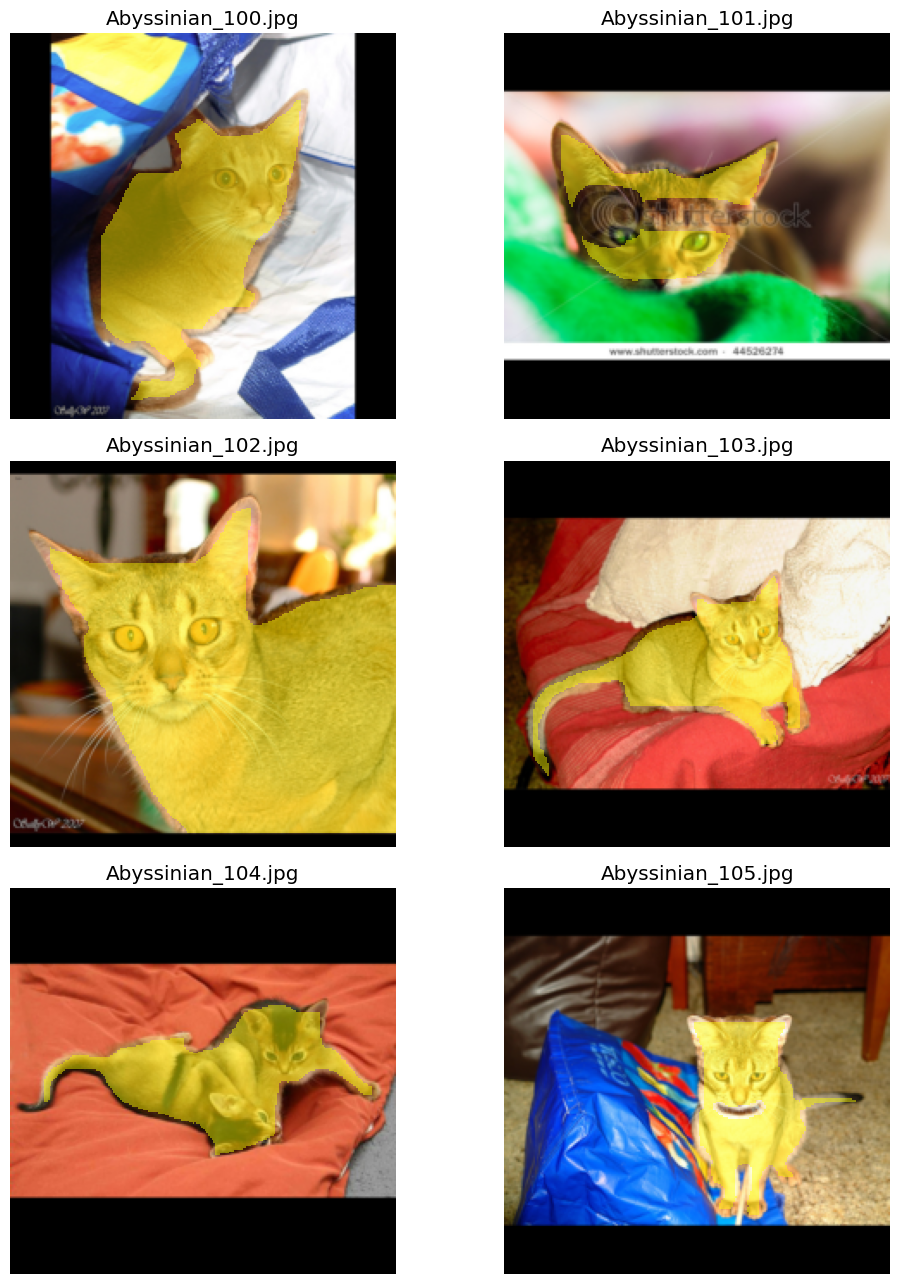

In [ ]:
# Visualización de seis imágenes con sus máscaras superpuestas.
# Utilizamos split_idx=1 para aplicar una transformación determinista
# e idéntica a las imágenes y a sus correspondientes máscaras.
resize = Resize(224, method=ResizeMethod.Pad, pad_mode=PadMode.Zeros)

fig, axes = plt.subplots(3, 2, figsize=(11, 13))

for ax, f in zip(axes.flat, trainval_files[:6]):

    # Cargar la imagen y la máscara original.
    img = PILImage.create(f)
    mask = pet_binary_mask(f) # la función pet_binary_mask() carga el trimap original
                              # y transforma sus etiquetas según la correspondencia indicada: 1 (animal),  0 (fondo), 255 (contorno incierto)

    # Aplicar el mismo redimensionamiento geométrico.
    img = resize(img, split_idx=1)
    mask = resize(mask, split_idx=1)

    # Convertir a NumPy para su visualización.
    rgb = np.asarray(img.convert('RGB'), dtype=np.float32) / 255.0
    m = np.asarray(mask)

    # Mostrar la imagen.
    ax.imshow(rgb)

    # Superponer exclusivamente los píxeles correspondientes al animal.
    ax.imshow(
        np.ma.masked_where(m != 1, m),
        cmap='autumn',
        alpha=0.45,
        interpolation='nearest',
        vmin=0,
        vmax=1
    )

    ax.set_title(f.name)
    ax.axis('off')

plt.tight_layout()
plt.show()


In [ ]:
# A COMPLETAR POR EL ALUMNADO

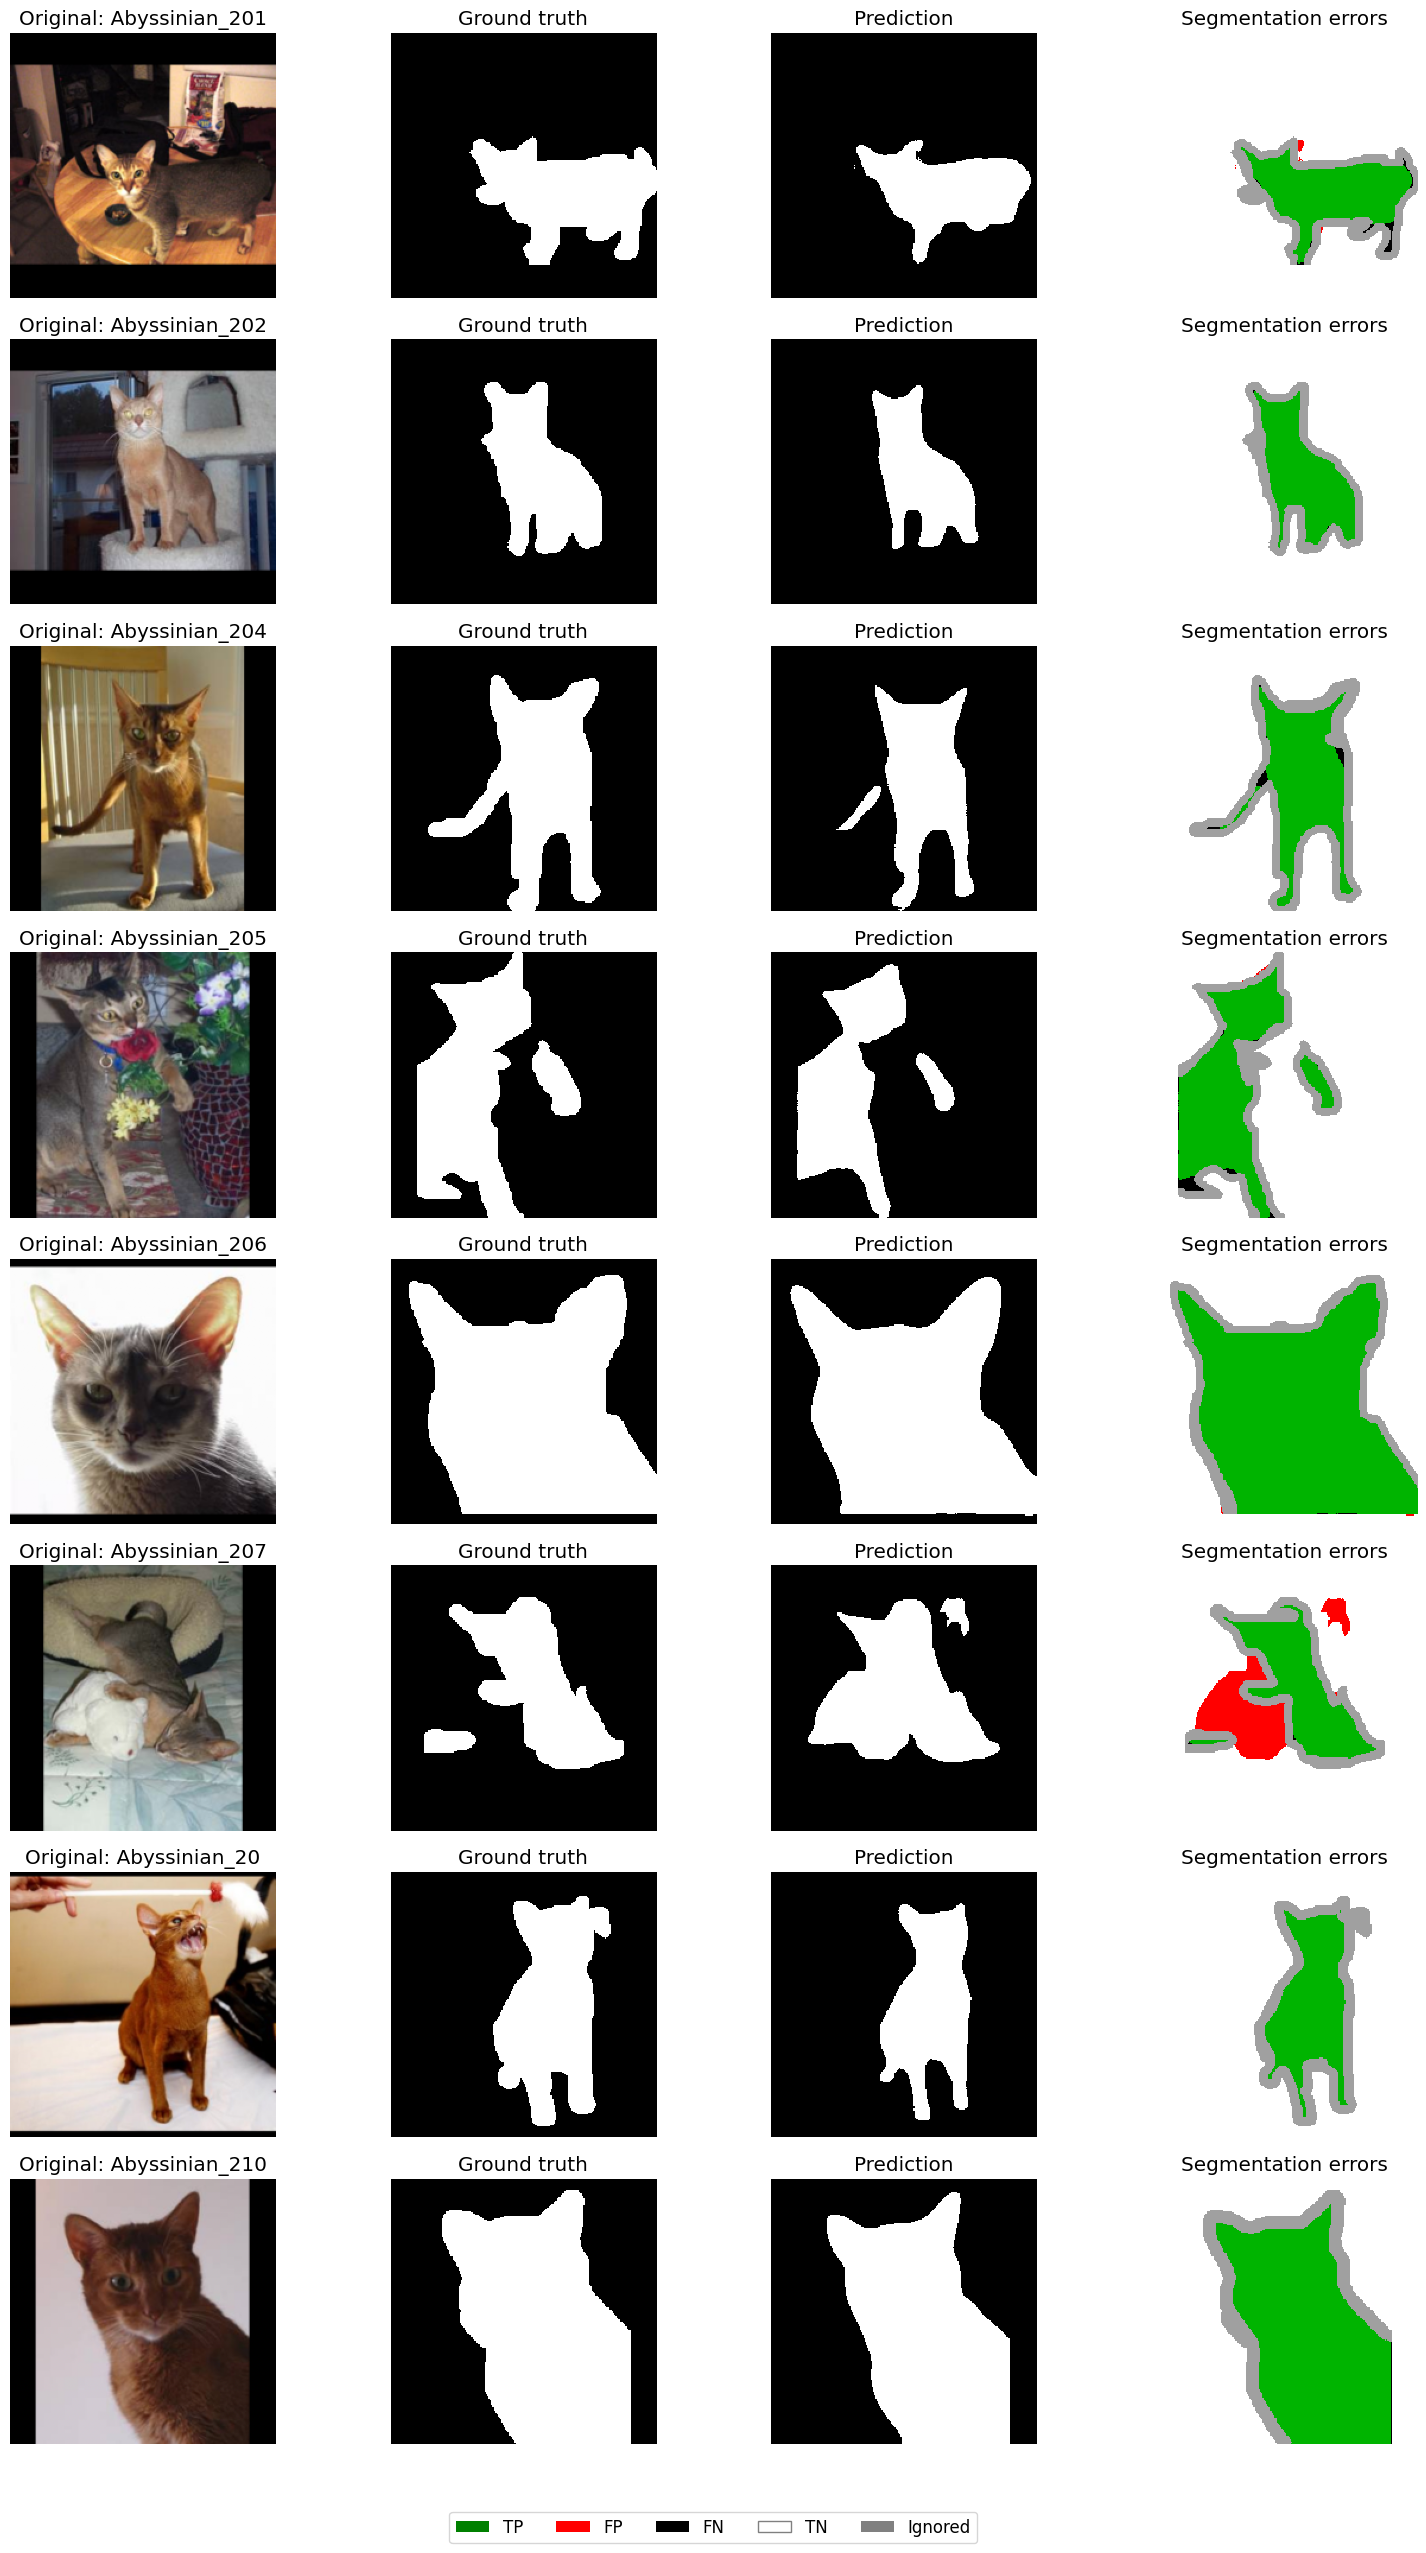

In [ ]:
# A COMPLETAR POR EL ALUMNADO